# Iris Flower Classification and Machine Learning

An end-to-end machine learning study on the Iris dataset: exploratory data analysis, linear regression, classical classification models (Logistic Regression, Random Forest, KNN, SVM), unsupervised K-Means clustering with PCA, and deep learning architectures (MLP, 1D-CNN, Tabular Transformer) using Scikit-Learn and PyTorch.

## 1. Setup

In [1]:
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, r2_score, mean_squared_error,
    silhouette_score, adjusted_rand_score,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Loading the data

The file has an `Id` column that is just a row counter, so we will drop it before modelling.

In [2]:
df = pd.read_csv("Iris.csv")
print("Shape:", df.shape)
df.head()

Shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Id,150.0,75.50,43.45,1.0,38.25,75.50,112.75,150.0
SepalLengthCm,150.0,5.84,0.83,4.3,5.10,5.80,6.40,7.9
SepalWidthCm,150.0,3.05,0.43,2.0,2.80,3.00,3.30,4.4
PetalLengthCm,150.0,3.76,1.76,1.0,1.60,4.35,5.10,6.9
PetalWidthCm,150.0,1.20,0.76,0.1,0.30,1.30,1.80,2.5


In [5]:
print("Missing values:", df.isnull().sum().sum())
print("Class balance:")
print(df["Species"].value_counts())

Missing values: 0
Class balance:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


Nothing is missing and the classes are perfectly balanced at 50 each, which makes accuracy a fair metric here.

I also checked for duplicate rows. There are three rows that repeat an earlier measurement exactly (ignoring the `Id`). This is a known quirk of the original Iris data, and these look like genuine repeated measurements rather than copy errors, so I will keep them.

In [6]:
features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
print("Duplicate feature rows:", df.drop(columns="Id").duplicated().sum())
df[df.drop(columns="Id").duplicated(keep=False)]

Duplicate feature rows: 3


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
9,10,4.9,3.1,1.5,0.1,Iris-setosa
34,35,4.9,3.1,1.5,0.1,Iris-setosa
37,38,4.9,3.1,1.5,0.1,Iris-setosa
101,102,5.8,2.7,5.1,1.9,Iris-virginica
142,143,5.8,2.7,5.1,1.9,Iris-virginica


## 3. Exploratory data analysis

Before fitting anything, I want to see how the species differ.

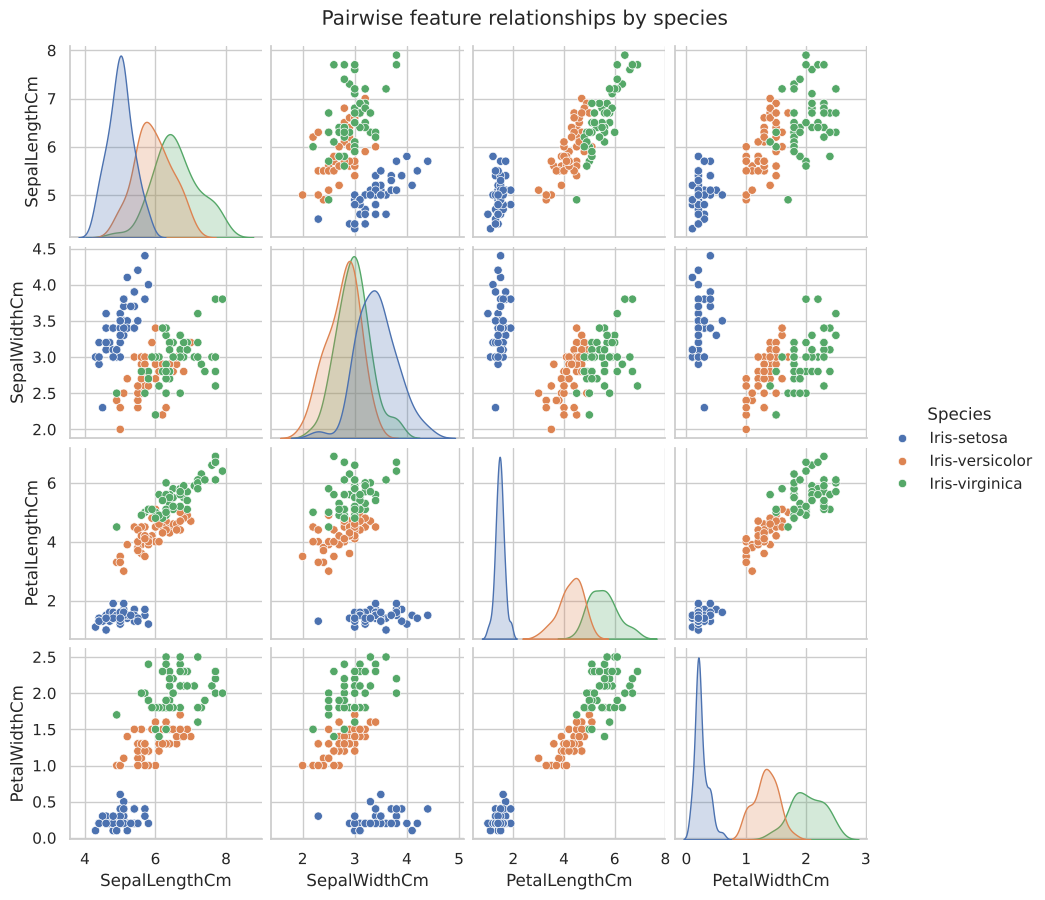

In [7]:
sns.pairplot(df.drop(columns="Id"), hue="Species", diag_kind="kde", height=2.2)
plt.suptitle("Pairwise feature relationships by species", y=1.02)
plt.show()

The petal measurements look like they separate the species much more cleanly than the sepal ones. Let's check that with boxplots and a correlation heatmap.

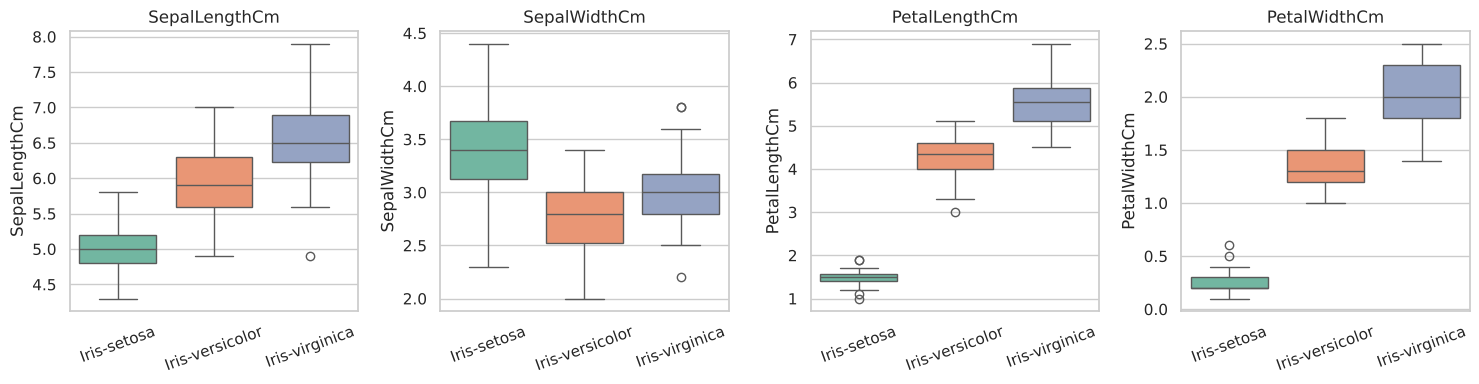

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, features):
    sns.boxplot(x="Species", y=col, data=df, hue="Species", palette="Set2", legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

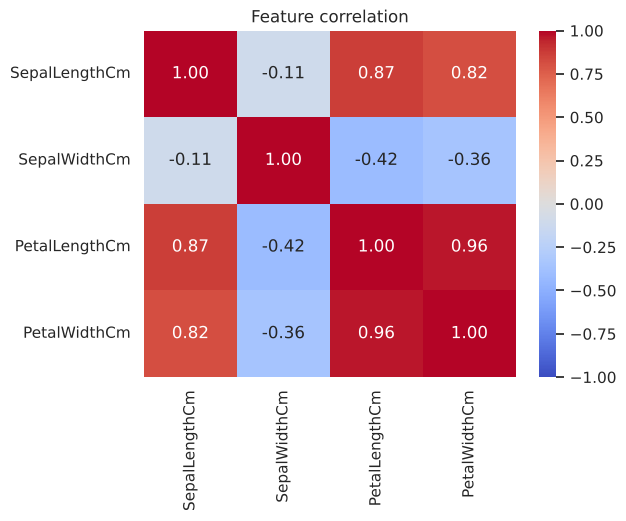

In [9]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Feature correlation")
plt.show()

Petal length and petal width are strongly correlated (about 0.96), so they carry much of the same information. Sepal width behaves differently: it is negatively correlated with the petal measurements (about -0.4) and almost unrelated to sepal length. Keep that in mind when reading the feature importances later.

## 4. Preparing the data

I split first and then scale. Fitting the scaler only on the training set keeps information from the test set out of the model.

In [10]:
X = df[features]
le = LabelEncoder()
y = le.fit_transform(df["Species"])
class_names = le.classes_
print("Label mapping:", dict(zip(class_names, range(len(class_names)))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Label mapping: {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}
Train size: 120 | Test size: 30


## 5. Linear regression

Linear regression needs a numeric target, and the species is a category. So for this model I will predict a continuous measurement instead: `PetalWidthCm`, using the other three measurements as inputs.

In [11]:
reg_features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    df[reg_features], df["PetalWidthCm"], test_size=0.2, random_state=RANDOM_STATE
)

lin_reg = LinearRegression().fit(Xr_train, yr_train)
pred_r = lin_reg.predict(Xr_test)

print(f"R^2:  {r2_score(yr_test, pred_r):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(yr_test, pred_r)):.3f} cm")
print("\nCoefficients:")
print(pd.Series(lin_reg.coef_, index=reg_features).round(3))

R^2:  0.927
RMSE: 0.215 cm

Coefficients:
SepalLengthCm   -0.238
SepalWidthCm     0.243
PetalLengthCm    0.537
dtype: float64


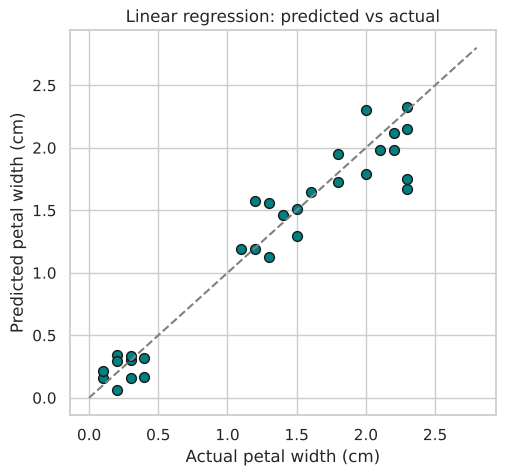

In [12]:
plt.figure(figsize=(5.5, 5))
plt.scatter(yr_test, pred_r, color="teal", edgecolor="k", s=50)
lims = [0, 2.8]
plt.plot(lims, lims, "--", color="gray")
plt.xlabel("Actual petal width (cm)")
plt.ylabel("Predicted petal width (cm)")
plt.title("Linear regression: predicted vs actual")
plt.show()

An R² close to 0.93 means a straight line over these measurements explains most of the variation in petal width, which fits the strong petal correlation we saw earlier.

## 6. Logistic regression (the classifier)

For the actual species prediction we use logistic regression. It is still a linear model, but it outputs class probabilities through a softmax.

In [13]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_s, y_train)
pred_lr = log_reg.predict(X_test_s)

print("Test accuracy:", round(accuracy_score(y_test, pred_lr), 3))
print(classification_report(y_test, pred_lr, target_names=class_names))

Test accuracy: 0.933
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



In [14]:
proba = pd.DataFrame(log_reg.predict_proba(X_test_s[:6]), columns=class_names).round(3)
proba["true_species"] = class_names[y_test[:6]]
proba

,Iris-setosa,Iris-versicolor,Iris-virginica,true_species
0,0.979,0.021,0.000,Iris-setosa
1,0.004,0.369,0.627,Iris-virginica
2,0.150,0.842,0.009,Iris-versicolor
3,0.096,0.894,0.010,Iris-versicolor
4,0.989,0.011,0.000,Iris-setosa
5,0.018,0.676,0.306,Iris-versicolor


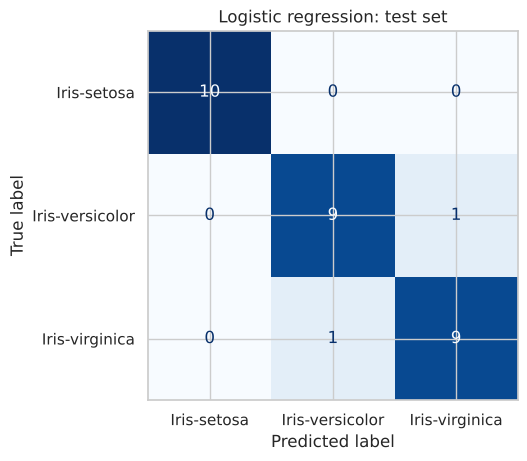

In [15]:
def show_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", colorbar=False)
    plt.title(title)
    plt.show()

show_confusion(y_test, pred_lr, "Logistic regression: test set")

## 7. Random forest

Tree ensembles do not need scaling, so this model uses the raw features.

Default random forest test accuracy: 0.9


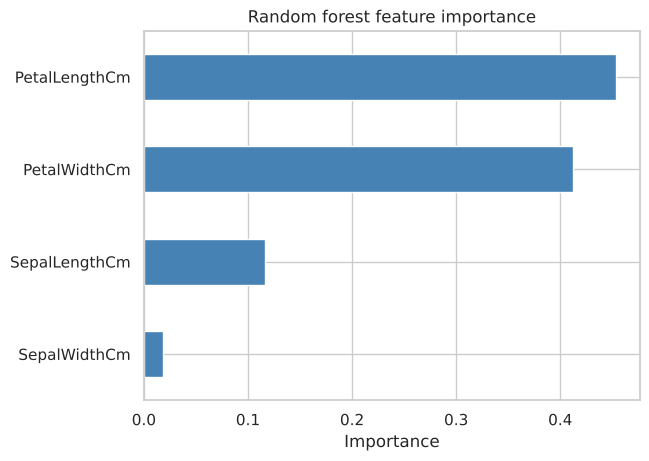

In [16]:
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
print("Default random forest test accuracy:", round(accuracy_score(y_test, pred_rf), 3))

importances = pd.Series(rf.feature_importances_, index=features).sort_values()
importances.plot(kind="barh", color="steelblue")
plt.title("Random forest feature importance")
plt.xlabel("Importance")
plt.show()

Petal length and width dominate, which matches what the boxplots showed. Next I'll tune the forest with a cross-validated grid search.

In [17]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 2, 3, 4],
    "min_samples_split": [2, 4],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid, cv=cv, scoring="f1_macro", n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV macro-F1:", round(grid.best_score_, 3))
best_rf = grid.best_estimator_

Best parameters: {'max_depth': None, 'min_samples_split': 4, 'n_estimators': 50}
Best CV macro-F1: 0.966


## 8. Comparing the classical models

To be fair to each model I compare them with 5-fold cross-validation on the training set first, then check them once on the held-out test set. Scaling lives inside each pipeline so it is re-fitted inside every fold.

In [18]:
candidates = {
    "Logistic regression": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]),
    "KNN (k=5)": Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=5))]),
    "SVM (RBF kernel)": Pipeline([("scale", StandardScaler()), ("clf", SVC(kernel="rbf"))]),
    "Random forest (tuned)": best_rf,
}

rows = []
for name, model in candidates.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    rows.append({
        "model": name,
        "cv_accuracy_mean": cv_scores.mean(),
        "cv_accuracy_std": cv_scores.std(),
        "test_accuracy": accuracy_score(y_test, preds),
        "test_macro_f1": f1_score(y_test, preds, average="macro"),
    })

classical_results = pd.DataFrame(rows).set_index("model").round(3)
classical_results

,cv_accuracy_mean,cv_accuracy_std,test_accuracy,test_macro_f1
model,,,,
Logistic regression,0.958,0.026,0.933,0.933
KNN (k=5),0.958,0.026,0.933,0.933
SVM (RBF kernel),0.967,0.017,0.967,0.967
Random forest (tuned),0.967,0.031,0.933,0.933


## 9. K-Means clustering

K-Means does not see the labels at all. It is a useful check on whether the measurements alone carry the species structure. I'll scale all the features here, since clustering is unsupervised and there is no train/test split involved.

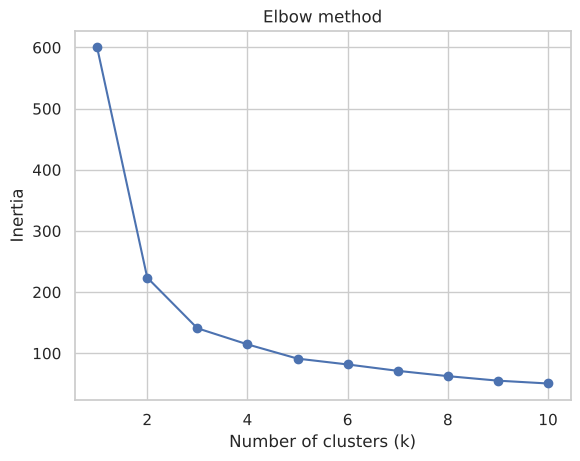

In [19]:
X_all_s = StandardScaler().fit_transform(X)

inertias = []
k_values = range(1, 11)
for k in k_values:
    inertias.append(KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_all_s).inertia_)

plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.show()

In [20]:
for k in range(2, 7):
    labels_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_all_s)
    print(f"k={k}  silhouette={silhouette_score(X_all_s, labels_k):.3f}")

k=2  silhouette=0.580
k=3  silhouette=0.459
k=4  silhouette=0.385
k=5  silhouette=0.347
k=6  silhouette=0.341


In [21]:
km = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
clusters = km.fit_predict(X_all_s)

print("Adjusted Rand index vs true species:", round(adjusted_rand_score(y, clusters), 3))
pd.crosstab(df["Species"], clusters, rownames=["True species"], colnames=["Cluster"])

Adjusted Rand index vs true species: 0.62


Cluster,0,1,2
True species,,,
Iris-setosa,0,50,0
Iris-versicolor,39,0,11
Iris-virginica,14,0,36


Variance explained by 2 components: [0.728 0.23 ] total: 0.958


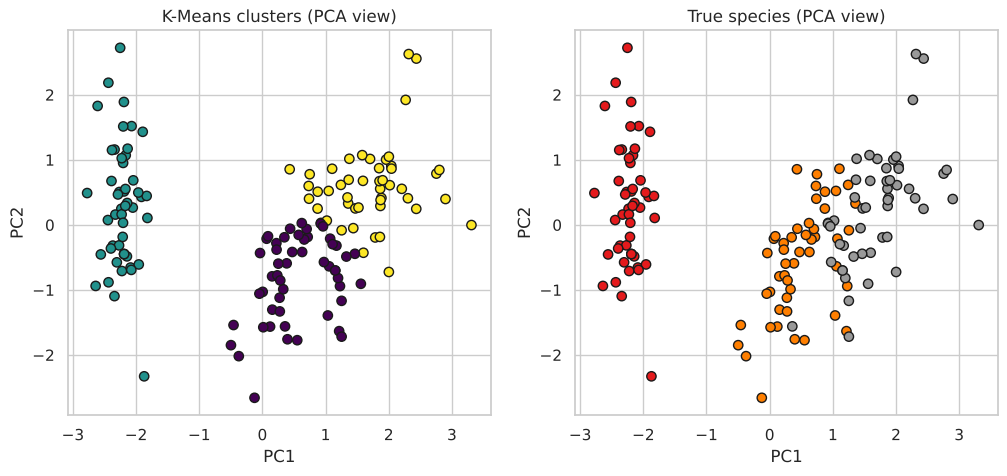

In [22]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_all_s)
print("Variance explained by 2 components:", pca.explained_variance_ratio_.round(3), "total:", round(pca.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap="viridis", s=45, edgecolor="k")
axes[0].set_title("K-Means clusters (PCA view)")
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="Set1", s=45, edgecolor="k")
axes[1].set_title("True species (PCA view)")
for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.show()

K-Means recovers the setosa group cleanly. Versicolor and virginica overlap a little, so the clusters do not match the species perfectly, which the adjusted Rand index quantifies.

## 10. Neural networks

Iris is a small tabular dataset, so a plain MLP is the natural neural network here. The user also asked for CNNs and Transformers, so I have included both. A caveat: a CNN is built for spatial structure (like pixels) and a Transformer for sequences, while Iris has just four numbers per flower with no spatial layout. I treat the four features as a tiny sequence so the architectures can run. I would not expect them to beat the MLP or the forest on this data, and the results below will show that.

All three networks use the same training loop. I carve a validation set out of the training data for early stopping, and keep the test set untouched until the end.

In [23]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(RANDOM_STATE)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

X_tr_nn, X_val_nn, y_tr_nn, y_val_nn = train_test_split(
    X_train_s, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)

def to_tensors(X_arr, y_arr):
    return torch.tensor(X_arr, dtype=torch.float32), torch.tensor(y_arr, dtype=torch.long)

Xtr_t, ytr_t = to_tensors(X_tr_nn, y_tr_nn)
Xva_t, yva_t = to_tensors(X_val_nn, y_val_nn)
Xte_t, yte_t = to_tensors(X_test_s, y_test)

print("Train:", Xtr_t.shape, "| Val:", Xva_t.shape, "| Test:", Xte_t.shape)

Using device: cpu
Train: torch.Size([96, 4]) | Val: torch.Size([24, 4]) | Test: torch.Size([30, 4])


In [24]:
class MLP(nn.Module):
    def __init__(self, n_in=4, n_out=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 32), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, n_out),
        )

    def forward(self, x):
        return self.net(x)


class CNN1D(nn.Module):
    # The four features are treated as a length-4 signal with one channel.
    def __init__(self, n_out=3):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=2, padding=1), nn.ReLU(),
            nn.Conv1d(16, 32, kernel_size=2, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        self.head = nn.Linear(32, n_out)

    def forward(self, x):
        x = x.unsqueeze(1)           # (batch, 1, 4)
        x = self.conv(x).squeeze(-1)  # (batch, 32)
        return self.head(x)


class TinyTransformer(nn.Module):
    # Each feature becomes a token, embedded and passed through self-attention.
    def __init__(self, n_features=4, d_model=16, n_out=3):
        super().__init__()
        self.token_embed = nn.Linear(1, d_model)
        self.pos_embed = nn.Parameter(torch.zeros(1, n_features, d_model))
        layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=2, dim_feedforward=32, dropout=0.1, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=2)
        self.head = nn.Linear(d_model, n_out)

    def forward(self, x):
        tokens = self.token_embed(x.unsqueeze(-1)) + self.pos_embed  # (batch, 4, d_model)
        encoded = self.encoder(tokens)
        return self.head(encoded.mean(dim=1))

In [25]:
def train_model(model, Xtr, ytr, Xva, yva, epochs=300, lr=0.01, batch_size=16):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True)

    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val, best_state = float("inf"), None

    for epoch in range(epochs):
        model.train()
        running = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)

        model.eval()
        with torch.no_grad():
            val_logits = model(Xva.to(device))
            val_loss = loss_fn(val_logits, yva.to(device)).item()
            val_acc = (val_logits.argmax(dim=1).cpu() == yva).float().mean().item()

        history["train_loss"].append(running / len(Xtr))
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_loss < best_val:
            best_val = val_loss
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return model, history

torch.manual_seed(RANDOM_STATE)
mlp, mlp_hist = train_model(MLP(), Xtr_t, ytr_t, Xva_t, yva_t)

torch.manual_seed(RANDOM_STATE)
cnn, cnn_hist = train_model(CNN1D(), Xtr_t, ytr_t, Xva_t, yva_t)

torch.manual_seed(RANDOM_STATE)
transformer, tf_hist = train_model(TinyTransformer(), Xtr_t, ytr_t, Xva_t, yva_t)

print("Training finished.")
print("MLP best val acc:        ", round(max(mlp_hist["val_acc"]), 3))
print("CNN best val acc:        ", round(max(cnn_hist["val_acc"]), 3))
print("Transformer best val acc:", round(max(tf_hist["val_acc"]), 3))

Training finished.
MLP best val acc:         0.958
CNN best val acc:         1.0
Transformer best val acc: 1.0


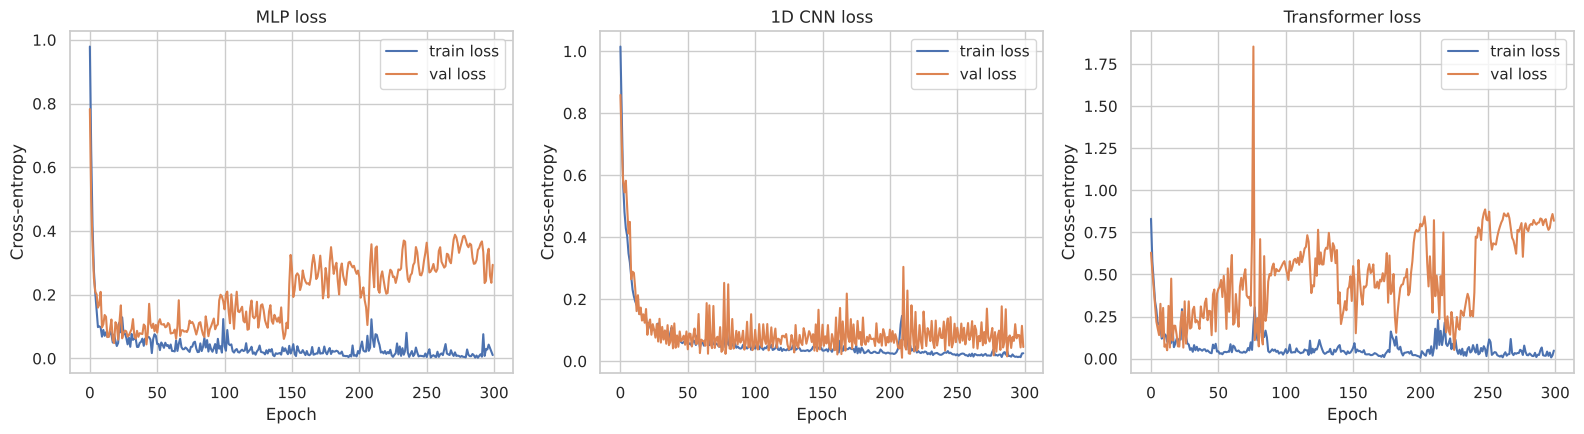

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, hist, title in zip(axes, [mlp_hist, cnn_hist, tf_hist], ["MLP", "1D CNN", "Transformer"]):
    ax.plot(hist["train_loss"], label="train loss")
    ax.plot(hist["val_loss"], label="val loss")
    ax.set_title(f"{title} loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy")
    ax.legend()
plt.tight_layout()
plt.show()

In [27]:
def predict_nn(model, X_t):
    model.eval()
    with torch.no_grad():
        return model(X_t.to(device)).argmax(dim=1).cpu().numpy()

nn_results = []
for name, model in [("MLP (neural net)", mlp), ("1D CNN", cnn), ("Transformer", transformer)]:
    preds = predict_nn(model, Xte_t)
    nn_results.append({
        "model": name,
        "cv_accuracy_mean": np.nan,
        "cv_accuracy_std": np.nan,
        "test_accuracy": accuracy_score(y_test, preds),
        "test_macro_f1": f1_score(y_test, preds, average="macro"),
    })

nn_table = pd.DataFrame(nn_results).set_index("model").round(3)
nn_table

,cv_accuracy_mean,cv_accuracy_std,test_accuracy,test_macro_f1
model,,,,
MLP (neural net),NaN,NaN,0.933,0.933
1D CNN,NaN,NaN,0.900,0.898
Transformer,NaN,NaN,1.000,1.000


The networks are trained once with a single validation split, so they do not get the 5-fold cross-validation the classical models got. Their CV columns are left blank for that reason.

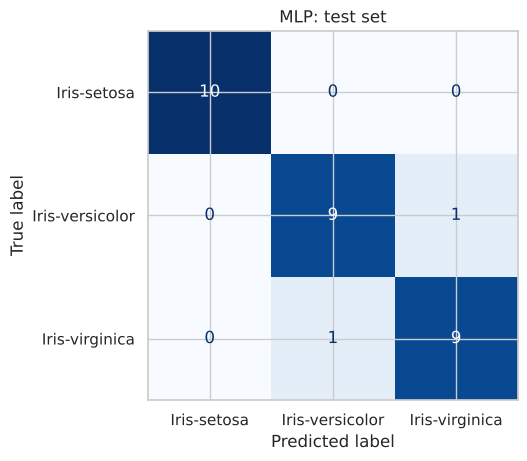

In [28]:
mlp_preds = predict_nn(mlp, Xte_t)
show_confusion(y_test, mlp_preds, "MLP: test set")

## 11. Final comparison

Now I put every model in one table.

In [29]:
all_results = pd.concat([classical_results, nn_table]).sort_values("test_macro_f1", ascending=False)
all_results

,cv_accuracy_mean,cv_accuracy_std,test_accuracy,test_macro_f1
model,,,,
Transformer,NaN,NaN,1.000,1.000
SVM (RBF kernel),0.967,0.017,0.967,0.967
Logistic regression,0.958,0.026,0.933,0.933
KNN (k=5),0.958,0.026,0.933,0.933
Random forest (tuned),0.967,0.031,0.933,0.933
MLP (neural net),NaN,NaN,0.933,0.933
1D CNN,NaN,NaN,0.900,0.898


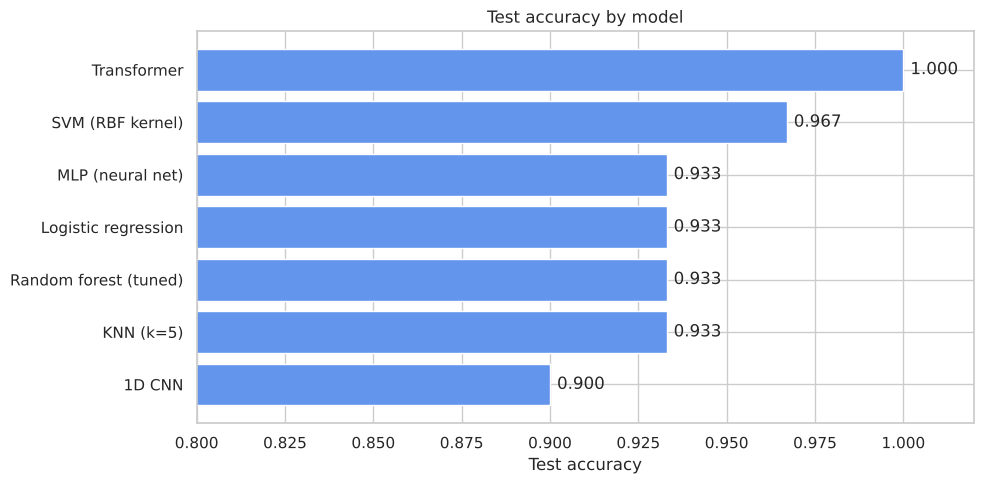

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = all_results["test_accuracy"].sort_values()
bars = ax.barh(plot_df.index, plot_df.values, color="cornflowerblue")
ax.set_xlim(0.8, 1.02)
ax.set_xlabel("Test accuracy")
ax.set_title("Test accuracy by model")
for bar, val in zip(bars, plot_df.values):
    ax.text(val + 0.002, bar.get_y() + bar.get_height() / 2, f"{val:.3f}", va="center")
plt.tight_layout()
plt.show()

In [31]:
all_results.to_csv("model_comparison.csv")
print("Saved model_comparison.csv")

Saved model_comparison.csv
